In [12]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import GridSearchCV, cross_val_predict
from xgboost import XGBClassifier

In [2]:
X_test = pd.read_csv("../data/processed/X_test.csv")
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

log_model = joblib.load("../models/logistic_regression.joblib")
rf_model = joblib.load("../models/random_forest.joblib")
xgb_model = joblib.load("../models/xgboost.joblib")

models = {
    "Logistic Regression": log_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

In [3]:
for name, model in models.items():
    y_pred = model.predict(X_test)
    print("=" * 50)
    print(name)
    print(classification_report(y_test, y_pred, target_names=["No Failure", "Failure"]))

Logistic Regression
              precision    recall  f1-score   support

  No Failure       1.00      0.86      0.92      1932
     Failure       0.18      0.88      0.30        68

    accuracy                           0.86      2000
   macro avg       0.59      0.87      0.61      2000
weighted avg       0.97      0.86      0.90      2000

Random Forest
              precision    recall  f1-score   support

  No Failure       0.99      1.00      1.00      1932
     Failure       0.96      0.81      0.88        68

    accuracy                           0.99      2000
   macro avg       0.98      0.90      0.94      2000
weighted avg       0.99      0.99      0.99      2000

XGBoost
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.82      0.82      0.82        68

    accuracy                           0.99      2000
   macro avg       0.91      0.91      0.91      2000
weighted avg       0.99      0.9

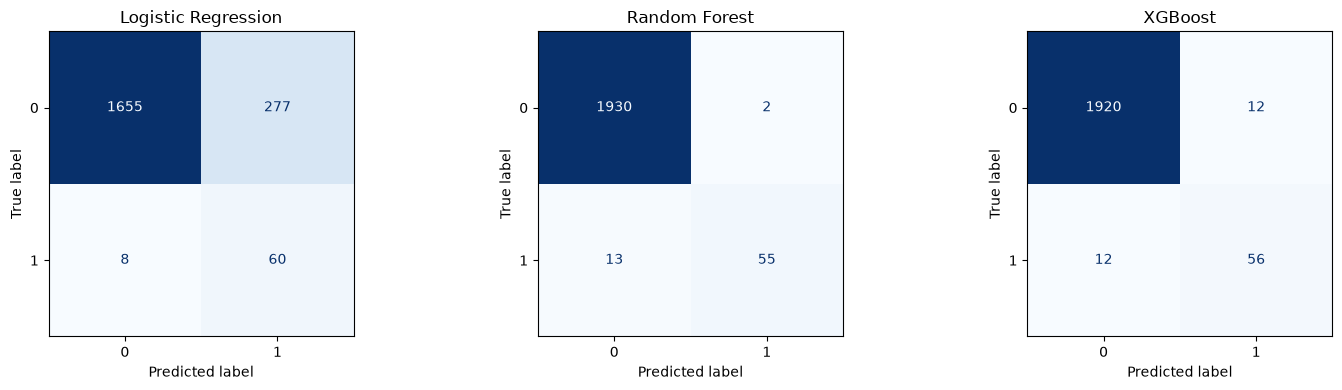

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [5]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": model.score(X_test, y_test),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.858,0.178,0.882,0.296,0.939,0.434
1,Random Forest,0.992,0.965,0.809,0.880,0.980,0.862
2,XGBoost,0.988,0.824,0.824,0.824,0.985,0.885


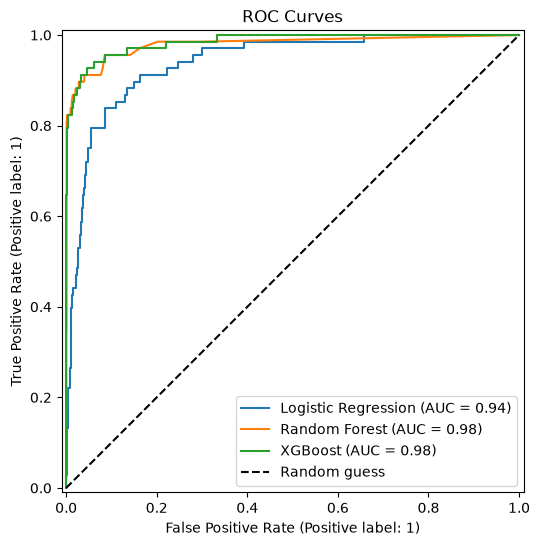

In [6]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(7, 6))
for name, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)

ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.legend()
plt.title("ROC Curves")
plt.show()

In [13]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", ratio)

scale_pos_weight: 28.52029520295203


In [14]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 4, 6],
    "learning_rate": [0.05, 0.1]
}

grid = GridSearchCV(
    XGBClassifier(scale_pos_weight=ratio, eval_metric="logloss", random_state=42),
    param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

In [15]:
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 3))

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best parameters: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 300}
Best CV F1: 0.815


Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best parameters: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 300}
Best CV F1: 0.815


In [16]:
best_model = grid.best_estimator_

In [17]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["No Failure", "Failure"]))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))
print("PR-AUC:", round(average_precision_score(y_test, y_prob), 3))

              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      1932
     Failure       0.88      0.82      0.85        68

    accuracy                           0.99      2000
   macro avg       0.93      0.91      0.92      2000
weighted avg       0.99      0.99      0.99      2000

ROC-AUC: 0.985
PR-AUC: 0.891


In [18]:
joblib.dump(best_model, "../models/final_model.joblib")

['../models/final_model.joblib']

In [19]:
train_prob = cross_val_predict(
    best_model, X_train, y_train, cv=5, method="predict_proba"
)[:, 1]

In [22]:
from sklearn.metrics import fbeta_score

In [23]:
thresholds = np.arange(0.1, 0.9, 0.05)
scores = [fbeta_score(y_train, train_prob >= t, beta=2) for t in thresholds]

best_t = thresholds[np.argmax(scores)]
print("Best threshold:", round(best_t, 2))

Best threshold: 0.6


In [24]:
y_pred_new = (y_prob >= best_t).astype(int)

print(classification_report(y_test, y_pred_new, target_names=["No Failure", "Failure"]))
print(confusion_matrix(y_test, y_pred_new))

              precision    recall  f1-score   support

  No Failure       0.99      1.00      1.00      1932
     Failure       0.92      0.82      0.87        68

    accuracy                           0.99      2000
   macro avg       0.96      0.91      0.93      2000
weighted avg       0.99      0.99      0.99      2000

[[1927    5]
 [  12   56]]


In [25]:
joblib.dump(best_t, "../models/threshold.joblib")

['../models/threshold.joblib']